In [1]:
# Run from the workshop root (workshops/w5): models/, evaluation/ and artifacts/ are resolved relative to it.
import os
import sys
from pathlib import Path
_here = Path.cwd().resolve()
W5_ROOT = next(p for p in (_here, *_here.parents) if p.name == "w5" and (p / "models").is_dir())
os.chdir(W5_ROOT)
for sub in ("models", "evaluation"):
    if str(W5_ROOT / sub) not in sys.path:
        sys.path.insert(0, str(W5_ROOT / sub))
print("cwd:", Path.cwd())

cwd: /home/alejandropenagos/Escritorio/Alejandro/Machine_Leaning/customer-churn-prediction/workshops/w5


# w5 · Wasserstein TimeGAN v2: convolutional (TCN) critic

This notebook continues `w5_gan_models.ipynb`, which is **kept unchanged** as the record of the first Wasserstein TimeGAN (**v1**, `artifacts/wtimegan/`). It has two parts:

1. **Why v1 falls short** (section 2): evidence computed from the saved v1 artifacts, read-only. In short, the code is correct, but v1 is **very inefficient**: its recurrent critic makes every training step ~11× more expensive than necessary, so the training that fits in a reasonable time gives the generator too few updates to learn the data.
2. **v2** (sections 3-6): same Wasserstein TimeGAN with a **temporal convolutional critic (TCN)**, which makes training efficient enough to give the generator a full budget. It is trained, evaluated and bridged to w2 with the same protocol as v1, and compared with TimeGAN.

v1 only appears in section 2, as the first attempt and the reason it was replaced. From section 5 on the comparison is **TimeGAN vs v2**.

| GAN | Adversarial loss | Critic / discriminator | Generator lr | Artifacts |
|---|---|---|---|---|
| TimeGAN | binary cross-entropy | GRU | 1e-3 | `artifacts/timegan/` |
| Wasserstein TimeGAN **v1** | WGAN-GP | GRU (cuDNN off) | 1e-4 | `artifacts/wtimegan/` |
| Wasserstein TimeGAN **v2** | WGAN-GP | **TCN** (Conv1D, cuDNN on) | **1e-3** | `artifacts/wtimegan_tcn/` |

The data protocol, the post-processing and every metric are the ones of `w5_gan_models.ipynb` (sections 2 and 4 there). New outputs go to `artifacts/wtimegan_tcn/`, `artifacts/evaluation_tcn/` and `artifacts/bridge_tcn/`; nothing of the first notebook is overwritten.

## 1. Configuration

- `NEW_GAN` / `NEW_PARAMS`: the v2 run. Changes with respect to v1 are marked in the table of section 3.
- `OLD_GANS`: runs of the first notebook, **loaded read-only** (`gan_runner.load_run`, no parameter check, never retrained).
- `ITERATIONS`: iterations of the embedding and supervised phases (same as TimeGAN and v1). `JOINT_ITERATIONS`: joint-phase iterations of v2. `W5_ITERATIONS=1000 W5_JOINT_ITERATIONS=600` gives a quick smoke run (~2.5 min per class on an RTX 3050).
- `COMPARE`: GANs compared in sections 5-6 (TimeGAN and v2; v1 stays in section 2).
- `RUN_BRIDGE`: retrain the w2 classifiers and trajectory models with the v2 users (section 6, several hours). With `False` the saved results of `artifacts/bridge_tcn/` are read instead.

In [2]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

warnings.filterwarnings("ignore")

from TimeGAN import TimeGAN, RNNNet
from WTimeGAN import wtimegan, TCNCritic
from gan_runner import train_or_load, load_run
from w2_sequences import MODEL_CHANNELS, postprocess
import gen_quality as gq
import gen_plots as gp
import w2_bridge as bridge

SEED = 110
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ITERATIONS = int(os.environ.get("W5_ITERATIONS", "10000"))
JOINT_ITERATIONS = int(os.environ.get("W5_JOINT_ITERATIONS", "10000"))
RETRAIN = False
RUN_BRIDGE = False             # True retrains the w2 models (hours); False reads artifacts/bridge_tcn/

NEW_GAN = "wtimegan_tcn"
NEW_PARAMS = {
    "hidden_dim": 56, "num_layer": 3, "iterations": ITERATIONS, "joint_iterations": JOINT_ITERATIONS,
    "batch_size": 128, "module": "gru", "seed": SEED,
    "n_critic": 5, "lambda_gp": 10.0, "gan_betas": [0.5, 0.9],
    "critic": "tcn", "critic_channels": 64,     # v2: convolutional critic
    "g_lr": 1e-3, "d_lr": 1e-4,                 # v2: generator at the TimeGAN learning rate
}
OLD_GANS = ("timegan", "wtimegan")              # first notebook, read-only
GANS = (*OLD_GANS, NEW_GAN)
COMPARE = ("timegan", NEW_GAN)   # sections 5-6; v1 only in section 2
LABELS = {"timegan": "TimeGAN", "wtimegan": "WTimeGAN v1 (GRU critic)",
          NEW_GAN: "WTimeGAN v2 (TCN critic)"}

GAN_LABELS = (1, 0)            # 1 = churn, 0 = stay
BRIDGE_MODELS = ("lstm", "gru")
AUG_FRACTIONS = (0.5, 1.0)
TRAJ_MODELS = ("lstm", "gru")
TRAJ_FRACTIONS = (0.5, 1.0)

ARTIFACTS = Path("artifacts")
EVAL_DIR = ARTIFACTS / "evaluation_tcn"
BRIDGE_DIR = ARTIFACTS / "bridge_tcn"
OLD_EVAL_DIR, OLD_BRIDGE_DIR = ARTIFACTS / "evaluation", ARTIFACTS / "bridge"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

print("device:", DEVICE)
pd.DataFrame({NEW_GAN: NEW_PARAMS})

device: cuda


,wtimegan_tcn
hidden_dim,56
num_layer,3
iterations,10000
joint_iterations,10000
batch_size,128
module,gru
seed,110
n_critic,5
lambda_gp,10.0
gan_betas,"[0.5, 0.9]"


In [3]:
data = bridge.load_w2_data()

real = {}      # (part, label) -> raw w2-encoded users, float32
for part in ("fit", "tune"):
    for label in GAN_LABELS:
        real[part, label] = data.raw_rows(bridge.real_rows(data, part, label))
specs = [next(s for s in data.channel_specs if s["name"] == c) for c in MODEL_CHANNELS]

old_runs = {(gan, label): load_run(ARTIFACTS, gan, label) for gan in OLD_GANS for label in GAN_LABELS}
pd.DataFrame([{"gan": gan, "label": label, "synthetic users": len(run["synthetic"]),
               "train minutes": run["run"]["train_seconds"] / 60, "folder": str(run["dir"])}
              for (gan, label), run in old_runs.items()])

train_feb rows:   111,751 | label month: 2017-02 | churn rate: 0.3215
test      rows:   113,870 | label month: 2017-03 | churn rate: 0.4110
sequence data: 225,621 rows | RAM cache on (needs 1.1 GB, limit 8 GB)


loaded raw tensor into RAM: (225621, 90, 14) float16 in 0.3s


,gan,label,synthetic users,train minutes,folder
0,timegan,1,26947,27.546667,artifacts/timegan/label1
1,timegan,0,56867,27.230000,artifacts/timegan/label0
2,wtimegan,1,26947,54.943333,artifacts/wtimegan/label1
3,wtimegan,0,56867,55.011667,artifacts/wtimegan/label0


## 2. Why the Wasserstein TimeGAN v1 falls short

v1 (`w5_gan_models.ipynb`) was meant to fix the mode collapse of TimeGAN (`TIMEGAN_DIAGNOSIS.md`). It did not: the discriminative score stayed at ~0.5 (trivial to tell real from synthetic), the stayers collapsed, the payments disappeared and the estimated Wasserstein distance **grew** during training instead of shrinking.

**The code was checked and is correct:** signs of the critic and generator losses, gradient penalty per user over the whole sequence with mixes of real and synthetic users, critic without sigmoid nor batch normalisation, `n_critic` steps with fresh batches. v1 trained as designed; the problem is that the design is **very inefficient**:

1. **The recurrent critic is expensive** (2.4). The gradient penalty differentiates the critic twice. cuDNN has no double backward for recurrent networks, so the GRU critic runs with cuDNN off, one day at a time: ~83 % of the v1 training time goes to the critic, and each critic step is ~11× slower than with a convolutional critic.
2. **So the generator got a small budget** (2.1-2.3). To keep the run at ~55 min per class, the joint phase was set to `iterations // n_critic` (the critic gets as many steps as the TimeGAN discriminator) with the WGAN-GP learning rate of 1e-4. That leaves the generator with 1/10 of the TimeGAN updates at 1/10 of its learning rate: ~1 % of the TimeGAN generator budget. Within that budget the generator progressed little, and the critic kept the lead. Giving it a TimeGAN-sized budget with the GRU critic would take ~9 h per class.

### 2.1 Training budget

Generator updates in the joint phase: TimeGAN does 2 per iteration, v1 one per iteration (and `n_critic` critic steps, the expensive part). The last column multiplies updates by learning rate: a rough measure of how far the optimiser can move the generator within the run.

In [4]:
budget = []
for gan in OLD_GANS:
    run = old_runs[gan, 1]["run"]
    if gan == "timegan":
        g_steps, d_steps, g_lr, d_lr = 2 * run["iterations"], run["iterations"], 1e-3, 1e-3
    else:
        g_steps = run["joint_iterations"]
        d_steps = run["joint_iterations"] * run["n_critic"]
        g_lr = d_lr = run["gan_lr"]
    budget.append({"gan": LABELS[gan], "generator updates": g_steps, "generator lr": g_lr,
                   "critic / discriminator updates": d_steps, "critic lr": d_lr,
                   "updates x lr (generator)": g_steps * g_lr,
                   "train minutes (label 1)": run["train_seconds"] / 60})
budget = pd.DataFrame(budget).set_index("gan")
budget["vs TimeGAN"] = budget["updates x lr (generator)"] / budget.loc["TimeGAN", "updates x lr (generator)"]
budget

,generator updates,generator lr,critic / discriminator updates,critic lr,updates x lr (generator),train minutes (label 1),vs TimeGAN
gan,,,,,,,
TimeGAN,20000,0.0010,10000,0.0010,20.0,27.546667,1.00
WTimeGAN v1 (GRU critic),2000,0.0001,10000,0.0001,0.2,54.943333,0.01


### 2.2 How far the v1 generator got

Two checks from the saved checkpoints and raw outputs:

- **Norm of the generator weights** after training vs a freshly initialised generator: a rough measure of how much the generator changed during training. TimeGAN's generator moves far from the initial norm; v1's moves little within its budget.
- **Activity between users vs within users** (`active` channel of the raw output, scaled to [0, 1]). Real users differ from each other (some listen almost every day, others rarely: high *between-user* spread). A generator early in training, fed with fresh noise every day, produces similar daily noise for everyone: little between-user spread, most of the variation is day to day.

In [5]:
def generator_norm(state_dict):
    return float(np.sqrt(sum((v.float() ** 2).sum() for k, v in state_dict.items()
                             if k.startswith("generator."))))


torch.manual_seed(SEED)
fresh_norm = generator_norm(TimeGAN(14, 56, 3, "gru").state_dict())
i_active = MODEL_CHANNELS.index("active")


def spread(X, lo, hi):
    a = (X[:, :, i_active] - lo) / (hi - lo + 1e-7)
    return a.mean(axis=1).std(), a.std(axis=1).mean()


rows = []
for label in GAN_LABELS:
    lo, hi = real["fit", label][:, :, i_active].min(), real["fit", label][:, :, i_active].max()
    b, w = spread(real["fit", label], lo, hi)
    rows.append({"label": label, "source": "real (fit)", "generator weight norm": np.nan,
                 "active: between users (sd)": b, "active: within user (sd)": w})
    rows.append({"label": label, "source": "generator at initialisation", "generator weight norm": fresh_norm,
                 "active: between users (sd)": np.nan, "active: within user (sd)": np.nan})
    for gan in OLD_GANS:
        ckpt = torch.load(old_runs[gan, label]["dir"] / "checkpoint.pt", map_location="cpu", weights_only=False)
        b, w = spread(old_runs[gan, label]["raw"], lo, hi)
        rows.append({"label": label, "source": LABELS[gan], "generator weight norm": generator_norm(ckpt["state_dict"]),
                     "active: between users (sd)": b, "active: within user (sd)": w})
pd.DataFrame(rows).set_index(["label", "source"]).round(3)

generator weight norm  \
label source                                               
1     real (fit)                                     NaN   
      generator at initialisation                 17.892   
      TimeGAN                                     48.209   
      WTimeGAN v1 (GRU critic)                    18.504   
0     real (fit)                                     NaN   
      generator at initialisation                 17.892   
      TimeGAN                                     49.914   
      WTimeGAN v1 (GRU critic)                    18.699   

                                   active: between users (sd)  \
label source                                                    
1     real (fit)                                        0.321   
      generator at initialisation                         NaN   
      TimeGAN                                           0.451   
      WTimeGAN v1 (GRU critic)                          0.014   
0     real (fit)                                        0.281   
      generator at initialisation                         NaN   
      TimeGAN                                           0.362   
      WTimeGAN v1 (GRU critic)                          0.398   

                                   active: within user (sd)  
label source                                                 
1     real (fit)                                      0.355  
      generator at initialisation                       NaN  
      TimeGAN                                         0.121  
      WTimeGAN v1 (GRU critic)                        0.474  
0     real (fit)                                      0.370  
      generator at initialisation                       NaN  
      TimeGAN                                         0.280  
      WTimeGAN v1 (GRU critic)                        0.242

### 2.3 The critic kept the lead

In a healthy WGAN-GP run the estimated Wasserstein distance rises while the critic learns and then **goes down** as the generator catches up. In v1 it only rises (label 1 is still rising at the last iteration): within its budget, the generator did not catch up.

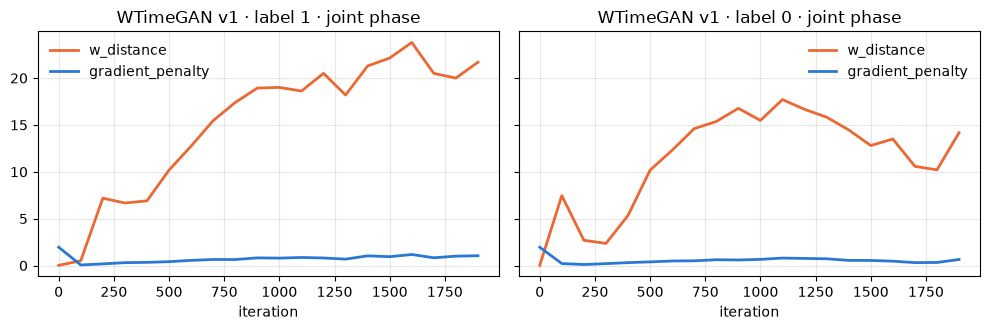

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, label in zip(axes, GAN_LABELS):
    h = old_runs["wtimegan", label]["history"]
    j = h[h["phase"] == "joint"]
    ax.plot(j["iteration"], j["w_distance"], linewidth=2, color="#eb6834", label="w_distance")
    ax.plot(j["iteration"], j["gradient_penalty"], linewidth=2, color="#2a78d6", label="gradient_penalty")
    ax.set_title(f"WTimeGAN v1 · label {label} · joint phase")
    ax.set_xlabel("iteration")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### 2.4 Efficiency: recurrent critic vs convolutional critic

Time of one critic step **with gradient penalty** (batch 128 × 90 days × 56 latent dims), on this machine. The GRU must run with cuDNN off; the TCN keeps cuDNN on.

In [7]:
def critic_step_ms(critic, cudnn, n=20, batch=128, days=90, hidden=56):
    critic = critic.to(DEVICE)
    opt = torch.optim.Adam(critic.parameters(), 1e-4)
    T = torch.full((batch,), days, dtype=torch.long)

    def score(x, t):
        return critic(x, t).squeeze(-1).mean(1)

    def step():
        real_h, fake_h = torch.rand(batch, days, hidden, device=DEVICE), torch.rand(batch, days, hidden, device=DEVICE)
        eps = torch.rand(batch, 1, 1, device=DEVICE)
        mix = (eps * real_h + (1 - eps) * fake_h).requires_grad_(True)
        with torch.backends.cudnn.flags(enabled=cudnn):
            g, = torch.autograd.grad(score(mix, T).sum(), mix, create_graph=True)
        loss = score(fake_h, T).mean() - score(real_h, T).mean() + 10 * ((g.flatten(1).norm(dim=1) - 1) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()

    for _ in range(3):
        step()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(n):
        step()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / n * 1000


torch.manual_seed(SEED)
speed = pd.DataFrame([
    {"critic": "GRU, 3 layers (v1, cuDNN off)", "ms per critic step": critic_step_ms(RNNNet("gru", 56, 56, 3, 1, None), cudnn=False)},
    {"critic": "TCN, 6 dilated Conv1D (v2, cuDNN on)", "ms per critic step": critic_step_ms(TCNCritic(56), cudnn=True)},
]).set_index("critic")
speed["speed-up"] = speed["ms per critic step"].iloc[0] / speed["ms per critic step"]
speed.round(1)

,ms per critic step,speed-up
critic,,
"GRU, 3 layers (v1, cuDNN off)",272.2,1.0
"TCN, 6 dilated Conv1D (v2, cuDNN on)",14.7,18.6


### 2.5 Consequences in the synthetic users

Mode-collapse signals of `TIMEGAN_DIAGNOSIS.md` (section 7) for both GANs of the first notebook. Real `tune` is the reference.

| Signal | Collapse looks like |
|---|---|
| `0 active days` / `>= 85 active days` | all-or-nothing users |
| `active switches (median)` | 0 = flat sequences; far above real = day-to-day noise |
| `no payment` | payments missing |
| `NN within` | far below real = near-copies of each other |
| `NN reference -> X` | far above real = real user types the GAN never generates |

In [8]:
def collapse_table(sources):
    rows = []
    for label in GAN_LABELS:
        fit_X, tune_X = real["fit", label], real["tune", label]
        rows.append({"label": label, "source": "real (tune)",
                     **gq.collapse_signals(fit_X, tune_X, MODEL_CHANNELS, reference=tune_X, seed=SEED)})
        for name, get in sources.items():
            rows.append({"label": label, "source": name,
                         **gq.collapse_signals(fit_X, get(label), MODEL_CHANNELS, reference=tune_X, seed=SEED)})
    return pd.DataFrame(rows).set_index(["label", "source"])


old_collapse = collapse_table({LABELS[g]: (lambda label, g=g: old_runs[g, label]["synthetic"]) for g in OLD_GANS})
old_collapse.round(3)

0 active days  >= 85 active days  \
label source                                                       
1     real (tune)                       0.045              0.085   
      TimeGAN                           0.465              0.266   
      WTimeGAN v1 (GRU critic)          0.000              0.000   
0     real (tune)                       0.002              0.147   
      TimeGAN                           0.054              0.085   
      WTimeGAN v1 (GRU critic)          0.000              0.559   

                                active switches (median)  no payment  \
label source                                                           
1     real (tune)                                   14.0       0.282   
      TimeGAN                                        0.0       0.649   
      WTimeGAN v1 (GRU critic)                      26.0       0.847   
0     real (tune)                                   17.0       0.145   
      TimeGAN                                       12.0       0.283   
      WTimeGAN v1 (GRU critic)                       1.0       0.830   

                                NN within  NN reference -> X  
label source                                                  
1     real (tune)                   5.574              5.568  
      TimeGAN                       0.161              7.128  
      WTimeGAN v1 (GRU critic)      1.094              9.076  
0     real (tune)                   6.089              6.166  
      TimeGAN                       5.935              7.159  
      WTimeGAN v1 (GRU critic)      0.456              7.566

**v1 in short.** Churners: no all-or-nothing users any more, but twice the real number of activity switches (day-to-day noise, typical of a generator early in training) and further from real users than TimeGAN. Stayers: collapsed (most users active almost every day, ~1 switch, near-copies). Payments: almost none. The loss is right; the run was too short for what each step costs, so these results say little yet about whether the Wasserstein loss helps.

A smoke run (1,000 / 1,000 / 600 iterations, churners) separated the two factors: with the TCN critic but the v1 generator learning rate (1e-4) the generator changed little (weight norm 17.9 → 18.3, between-user spread of `active` 0.05 vs 0.32 real), while with 1e-3 it progressed (17.9 → 21.5) and the moment loss dropped from 0.31 to 0.07. **The generator budget limits v1; the convolutional critic is what makes a full budget affordable.**

## 3. v2: what changes

| | v1 | v2 | Why |
|---|---|---|---|
| Critic | GRU, 3 layers, cuDNN off for the penalty | **TCN**: 6 dilated non-causal Conv1D layers (kernel 3, dilations 1-32, 64 channels, LeakyReLU, no normalisation), receptive field 127 ≥ 90 days | ~11× faster critic step (2.4): the efficiency that makes the larger budget affordable |
| Generator + supervisor lr | 1e-4 | **1e-3** (Adam default, as in TimeGAN) | the v1 generator progressed little within its budget (2.2) |
| Critic lr | 1e-4 | 1e-4 | WGAN-GP default |
| Joint iterations | 2,000 | **10,000** (= TimeGAN) | 5× more generator updates |
| `n_critic`, `lambda_gp`, Adam betas | 5, 10, (0.5, 0.9) | same | WGAN-GP defaults |
| Embedder, recovery, generator, supervisor, phases 1-2, `L_S`, `L_V` | GRU | **same** | only the critic is replaced |

**Is a convolutional critic compatible with TimeGAN?** Yes. The critic only talks to the rest of TimeGAN through the score it gives to a latent sequence; the generator receives the gradient of that score and does not depend on how it is computed.

- TimeGAN (Yoon et al., NeurIPS 2019) implements its discriminator as a *bidirectional* recurrent network and states that *"there are no restrictions on architecture beyond the generator being autoregressive"*; it names temporal convolutions as an option for its networks. The TCN critic is non-causal: like the paper's bidirectional discriminator, every output sees the whole sequence.
- WGAN-GP (Gulrajani et al., 2017) uses a 1D CNN critic for sequences (character-level language model), and WaveGAN (Donahue et al., ICLR 2019) trains a Conv1D discriminator with WGAN-GP on audio.
- A recurrent generator with a convolutional discriminator is a known combination for time series: BiLSTM-CNN GAN for ECG (Zhu et al., *Scientific Reports* 2019); Quant GANs (Wiese et al., *Quantitative Finance* 2020) use TCNs as discriminator for financial series. TCNs match or beat LSTM/GRU on sequence tasks (Bai, Kolter & Koltun, 2018).

What the WGAN-GP critic needs: a raw score (no sigmoid), no batch normalisation (it mixes users and breaks the per-user penalty), and a double backward on the GPU. The TCN meets the three.

**Caveat for the comparison:** v2 changes the critic architecture *and* the generator budget at once, and with respect to TimeGAN it also changes the loss. A gain of v2 over TimeGAN cannot be attributed to the Wasserstein loss alone.

## 4. Training

Same contract as the first notebook (`gan_runner.train_or_load`): one run per class in `artifacts/wtimegan_tcn/label<k>/`, reused when the parameters match. The joint-phase history now also logs `g_weight_norm`.

In [9]:
new_runs = {}
for label in GAN_LABELS:
    new_runs[label] = train_or_load(NEW_GAN, wtimegan, real["fit", label], specs, NEW_PARAMS, ARTIFACTS,
                                    label=label, retrain=RETRAIN)

runs = {**old_runs, **{(NEW_GAN, label): run for label, run in new_runs.items()}}
pd.DataFrame([{"gan": LABELS[NEW_GAN], "label": label, "train users": run["run"]["train_rows"],
               "synthetic users": len(run["synthetic"]), "train minutes": run["run"]["train_seconds"] / 60,
               "folder": str(run["dir"])} for label, run in new_runs.items()])

[wtimegan_tcn | label=1] reusing artifacts/wtimegan_tcn/label1


[wtimegan_tcn | label=0] reusing artifacts/wtimegan_tcn/label0


,gan,label,train users,synthetic users,train minutes,folder
0,WTimeGAN v2 (TCN critic),1,26947,26947,41.528333,artifacts/wtimegan_tcn/label1
1,WTimeGAN v2 (TCN critic),0,56867,56867,41.006667,artifacts/wtimegan_tcn/label0


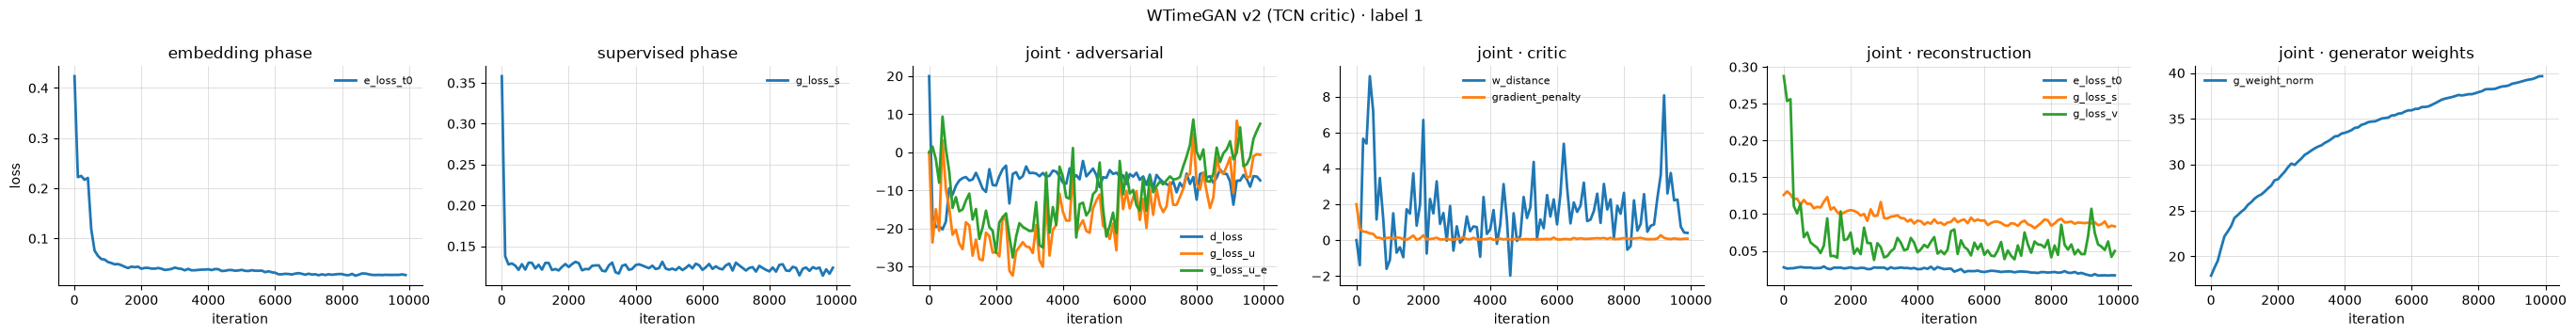

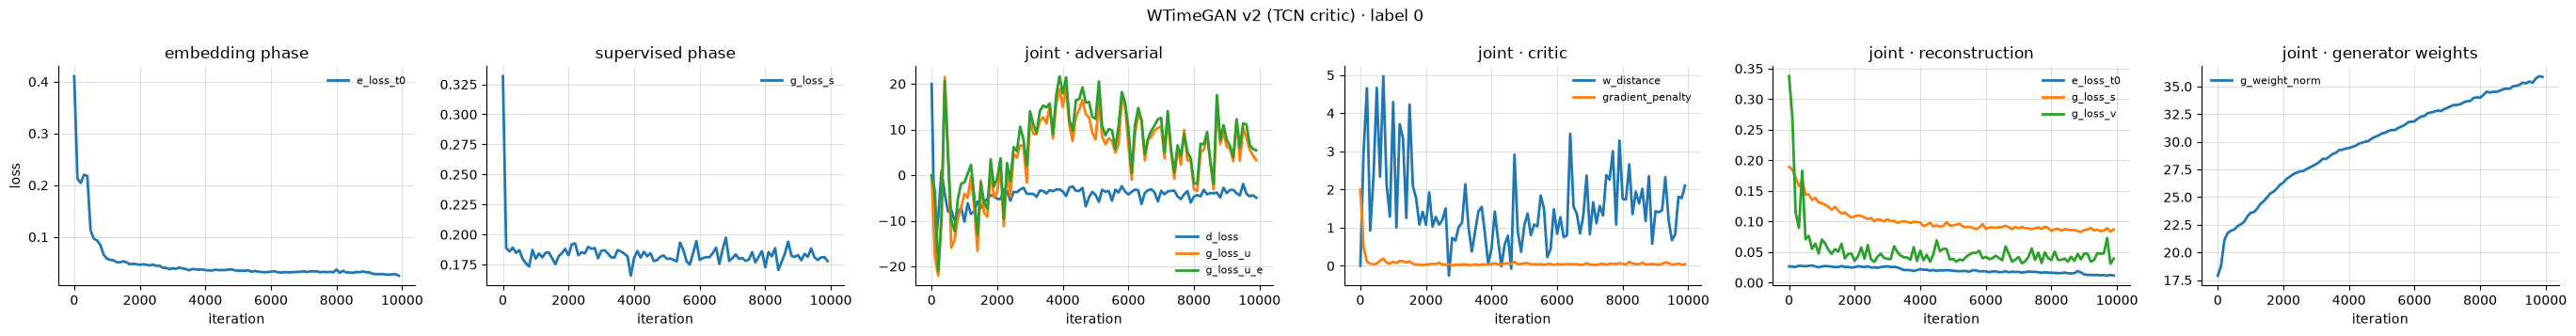

In [10]:
(EVAL_DIR / NEW_GAN).mkdir(parents=True, exist_ok=True)
for label, run in new_runs.items():
    gp.plot_gan_history(run["history"], f"{LABELS[NEW_GAN]} · label {label}",
                        save_path=EVAL_DIR / NEW_GAN / f"history_label{label}.png")
    plt.show()

### 4.1 Did the generator get further this time?

Three checks on the joint phase, the ones where v1 fell short:

1. `w_distance` over the **last 20 %** of the joint phase lower than its peak (the generator catches up with the critic).
2. Generator weight norm clearly above its initial value (v1: 17.9 → 18.5).
3. Between-user spread of `active` close to real (v1 churners: 0.014 vs 0.32).

In [11]:
checks = []
for label, run in new_runs.items():
    j = run["history"][run["history"]["phase"] == "joint"]
    tail = j[j["iteration"] >= 0.8 * j["iteration"].max()]
    lo, hi = real["fit", label][:, :, i_active].min(), real["fit", label][:, :, i_active].max()
    b_real, _ = spread(real["fit", label], lo, hi)
    b_new, w_new = spread(run["raw"], lo, hi)
    checks.append({
        "label": label,
        "w_distance peak": j["w_distance"].max(),
        "w_distance last 20 %": tail["w_distance"].mean(),
        "generator norm start": j["g_weight_norm"].iloc[0],
        "generator norm end": j["g_weight_norm"].iloc[-1],
        "active between users: real": b_real,
        "active between users: v2": b_new,
    })
checks = pd.DataFrame(checks).set_index("label")
checks["critic caught up"] = checks["w_distance last 20 %"] < 0.8 * checks["w_distance peak"]
checks["generator moved"] = checks["generator norm end"] > 1.1 * checks["generator norm start"]
checks.round(3)

,w_distance peak,w_distance last 20 %,generator norm start,generator norm end,active between users: real,active between users: v2,critic caught up,generator moved
label,,,,,,,,
1,9.144,1.83,17.895,39.648,0.321,0.309,True,True
0,4.972,1.61,17.896,35.861,0.281,0.357,True,True


## 5. Generation quality: TimeGAN vs v2

Same metrics as section 4 of `w5_gan_models.ipynb`. v1 is left out from here on (section 2 explains why it was replaced).

Every source is subsampled with a fresh generator seeded with `SEED`, the same evaluation as `run_experiments.py`, so these single-run numbers are directly comparable with the multi-seed runs of `artifacts/experiments/`.

### 5.1 Quantitative metrics

In [12]:
w2_lstm, w2_ckpt = bridge.load_w2_classifier("lstm")
W2_THRESHOLD = float(w2_ckpt["threshold"])


def lstm_view(X):
    scaled = bridge.scale(data, X, "development")
    return gq.lstm_features(w2_lstm, scaled, DEVICE), gq.churn_proba(w2_lstm, scaled, DEVICE)


quality_rows, marginals, aggregates_tables = [], {}, {}
features = {}

for label in GAN_LABELS:
    fit_X, tune_X = real["fit", label], real["tune", label]
    n_ref = len(tune_X)
    lo_q, hi_q = gq.minmax_fit(fit_X)
    fit_sub = fit_X[np.random.default_rng(SEED).choice(len(fit_X), n_ref, replace=False)]

    f_fit, p_fit = lstm_view(fit_sub)
    f_tune, p_tune = lstm_view(tune_X)
    features["real", label] = f_tune
    trtr = gq.predictive_score(fit_X, tune_X, lo=lo_q, hi=hi_q, device=DEVICE, seed=SEED)

    candidates = {"real (tune) [reference]": tune_X}
    candidates.update({gan: runs[gan, label]["synthetic"] for gan in COMPARE})
    for source, X in candidates.items():
        X_sub = X[np.random.default_rng(SEED).choice(len(X), n_ref, replace=False)] if len(X) > n_ref else X
        is_real = source.startswith("real")
        f_x, p_x = (f_tune, p_tune) if is_real else lstm_view(X_sub)
        if not is_real:
            features[source, label] = f_x
        disc = gq.discriminative_score(fit_X, X_sub, lo=lo_q, hi=hi_q, device=DEVICE, seed=SEED)
        pred = trtr if is_real else gq.predictive_score(X, tune_X, lo=lo_q, hi=hi_q, device=DEVICE, seed=SEED)
        quality_rows.append({
            "label": label, "source": source if is_real else LABELS[source],
            "Fréchet distance (w2 LSTM)": gq.frechet_distance(f_x, f_fit),
            "discriminative score": disc["discriminative score"],
            "predictive MAE (test on real tune)": pred,
            "mean churn proba (w2 LSTM)": p_x.mean(),
            "share classified as its label": ((p_x >= W2_THRESHOLD) == label).mean(),
        })
        if not is_real:
            marginals[source, label] = gq.marginal_table(fit_X, X, MODEL_CHANNELS)
            aggregates_tables[source, label] = gq.aggregate_table(fit_X, X, MODEL_CHANNELS)

quality = pd.DataFrame(quality_rows).set_index(["label", "source"])
quality.to_csv(EVAL_DIR / "quality_summary.csv")
quality.round(4)

Fréchet distance (w2 LSTM)  \
label source                                                 
1     real (tune) [reference]                       0.0083   
      TimeGAN                                       0.9636   
      WTimeGAN v2 (TCN critic)                      0.2420   
0     real (tune) [reference]                       0.0007   
      TimeGAN                                       0.0869   
      WTimeGAN v2 (TCN critic)                      0.0270   

                                discriminative score  \
label source                                           
1     real (tune) [reference]                 0.0153   
      TimeGAN                                 0.4794   
      WTimeGAN v2 (TCN critic)                0.3553   
0     real (tune) [reference]                 0.0010   
      TimeGAN                                 0.4780   
      WTimeGAN v2 (TCN critic)                0.4255   

                                predictive MAE (test on real tune)  \
label source                                                         
1     real (tune) [reference]                               0.1079   
      TimeGAN                                               0.0930   
      WTimeGAN v2 (TCN critic)                              0.0734   
0     real (tune) [reference]                               0.0917   
      TimeGAN                                               0.1049   
      WTimeGAN v2 (TCN critic)                              0.1072   

                                mean churn proba (w2 LSTM)  \
label source                                                 
1     real (tune) [reference]                       0.4764   
      TimeGAN                                       0.7529   
      WTimeGAN v2 (TCN critic)                      0.5136   
0     real (tune) [reference]                       0.2465   
      TimeGAN                                       0.3350   
      WTimeGAN v2 (TCN critic)                      0.2901   

                                share classified as its label  
label source                                                   
1     real (tune) [reference]                          0.7230  
      TimeGAN                                          0.9085  
      WTimeGAN v2 (TCN critic)                         0.7894  
0     real (tune) [reference]                          0.6805  
      TimeGAN                                          0.6022  
      WTimeGAN v2 (TCN critic)                         0.5702

### 5.2 Mode-collapse signals

In [13]:
collapse = collapse_table({LABELS[g]: (lambda label, g=g: runs[g, label]["synthetic"]) for g in COMPARE})
collapse.to_csv(EVAL_DIR / "collapse_signals.csv")
collapse.round(3)

0 active days  >= 85 active days  \
label source                                                       
1     real (tune)                       0.045              0.085   
      TimeGAN                           0.465              0.266   
      WTimeGAN v2 (TCN critic)          0.017              0.058   
0     real (tune)                       0.002              0.147   
      TimeGAN                           0.054              0.085   
      WTimeGAN v2 (TCN critic)          0.006              0.463   

                                active switches (median)  no payment  \
label source                                                           
1     real (tune)                                   14.0       0.282   
      TimeGAN                                        0.0       0.649   
      WTimeGAN v2 (TCN critic)                       9.0       0.461   
0     real (tune)                                   17.0       0.145   
      TimeGAN                                       12.0       0.283   
      WTimeGAN v2 (TCN critic)                       6.0       0.173   

                                NN within  NN reference -> X  
label source                                                  
1     real (tune)                   5.574              5.568  
      TimeGAN                       0.161              7.128  
      WTimeGAN v2 (TCN critic)      5.081              5.805  
0     real (tune)                   6.089              6.166  
      TimeGAN                       5.935              7.159  
      WTimeGAN v2 (TCN critic)      4.632              6.931

### 5.3 Marginals and per-user aggregates (v2)

In [14]:
for label in GAN_LABELS:
    print(f"\n===== {LABELS[NEW_GAN]} · label {label} · marginals =====")
    marginals[NEW_GAN, label].to_csv(EVAL_DIR / NEW_GAN / f"marginals_label{label}.csv")
    display(marginals[NEW_GAN, label].round(3))
    print(f"===== {LABELS[NEW_GAN]} · label {label} · aggregates =====")
    aggregates_tables[NEW_GAN, label].to_csv(EVAL_DIR / NEW_GAN / f"aggregates_label{label}.csv")
    display(aggregates_tables[NEW_GAN, label].round(3))


===== WTimeGAN v2 (TCN critic) · label 1 · marginals =====


,mean real,mean synth,std real,std synth,non-zero real,non-zero synth,W1 / std real
channel,,,,,,,
num_25,0.672,0.592,1.053,0.906,0.363,0.498,0.098
num_50,0.317,0.304,0.614,0.530,0.263,0.498,0.133
num_75,0.246,0.238,0.498,0.382,0.233,0.498,0.194
num_985,0.260,0.281,0.519,0.519,0.240,0.498,0.104
num_100,1.331,1.372,1.633,1.545,0.454,0.498,0.111
num_unq,1.399,1.339,1.654,1.545,0.468,0.498,0.063
total_secs,3.916,4.069,4.267,4.215,0.468,0.498,0.071
active,0.468,0.498,0.499,0.500,0.468,0.498,0.064
tx_count,0.011,0.019,0.090,0.114,0.015,0.026,0.090


===== WTimeGAN v2 (TCN critic) · label 1 · aggregates =====


,mean real,mean synth,KS
aggregate,,,
active days,42.130,44.843,0.056
active days (last 30),15.524,17.400,0.087
payment days,1.391,2.309,0.181
log hours listened,3.751,3.831,0.119
days to expire at cutoff,24.062,35.665,0.247
active-day switches,16.798,10.067,0.311



===== WTimeGAN v2 (TCN critic) · label 0 · marginals =====


,mean real,mean synth,std real,std synth,non-zero real,non-zero synth,W1 / std real
channel,,,,,,,
num_25,0.976,1.000,1.177,1.104,0.506,0.664,0.089
num_50,0.464,0.523,0.709,0.708,0.374,0.664,0.164
num_75,0.361,0.403,0.577,0.565,0.334,0.664,0.124
num_985,0.383,0.422,0.601,0.593,0.345,0.664,0.125
num_100,1.842,1.868,1.680,1.605,0.617,0.664,0.052
num_unq,1.934,1.959,1.686,1.614,0.632,0.664,0.074
total_secs,5.342,5.538,4.194,4.081,0.632,0.664,0.065
active,0.632,0.664,0.482,0.472,0.632,0.664,0.071
tx_count,0.016,0.017,0.105,0.107,0.023,0.024,0.012


===== WTimeGAN v2 (TCN critic) · label 0 · aggregates =====


,mean real,mean synth,KS
aggregate,,,
active days,56.907,59.783,0.385
active days (last 30),20.322,21.084,0.370
payment days,2.052,2.176,0.174
log hours listened,4.450,4.379,0.123
days to expire at cutoff,13.270,16.955,0.234
active-day switches,18.226,13.511,0.368


### 5.4 Qualitative assessment

PCA / t-SNE of the w2 LSTM features, **one figure per GAN** (real vs that GAN): synthetic points should cover the real cloud, not a sub-region nor a separate island. Then daily profiles, single users and aggregate histograms.

In [15]:
import importlib; importlib.reload(gp)

<module 'gen_plots' from '/home/alejandropenagos/Escritorio/Alejandro/Machine_Leaning/customer-churn-prediction/workshops/w5/evaluation/gen_plots.py'>

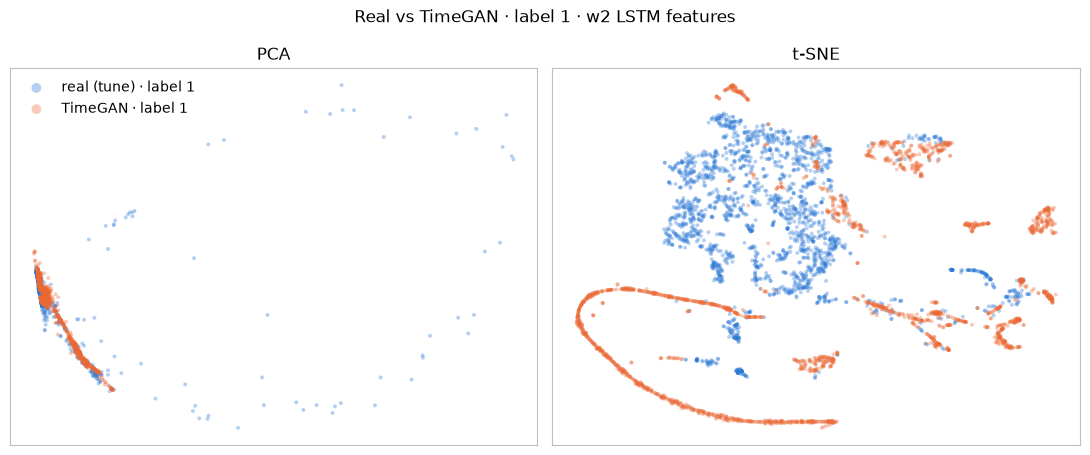

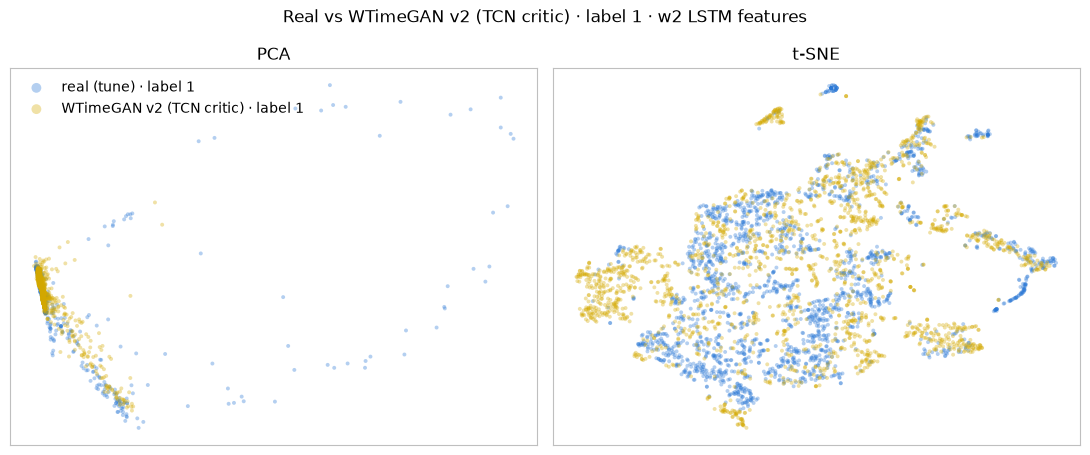

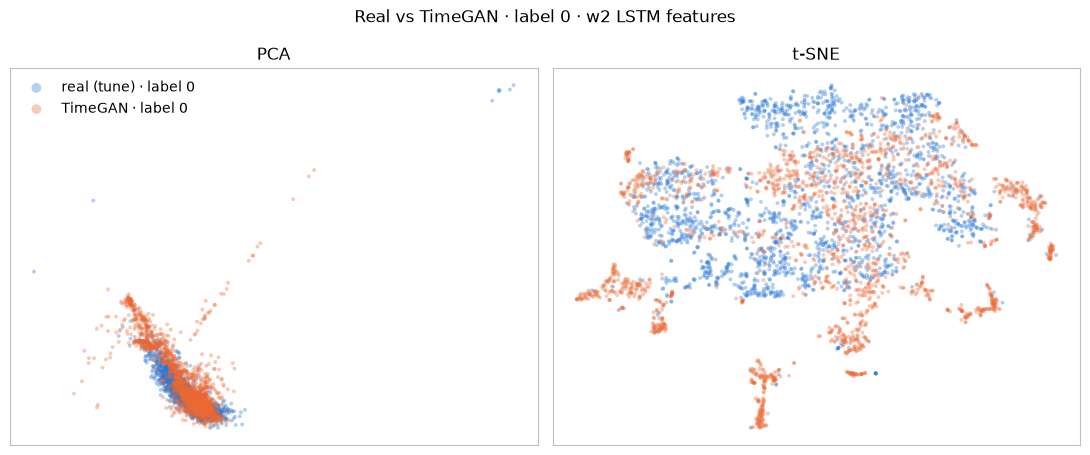

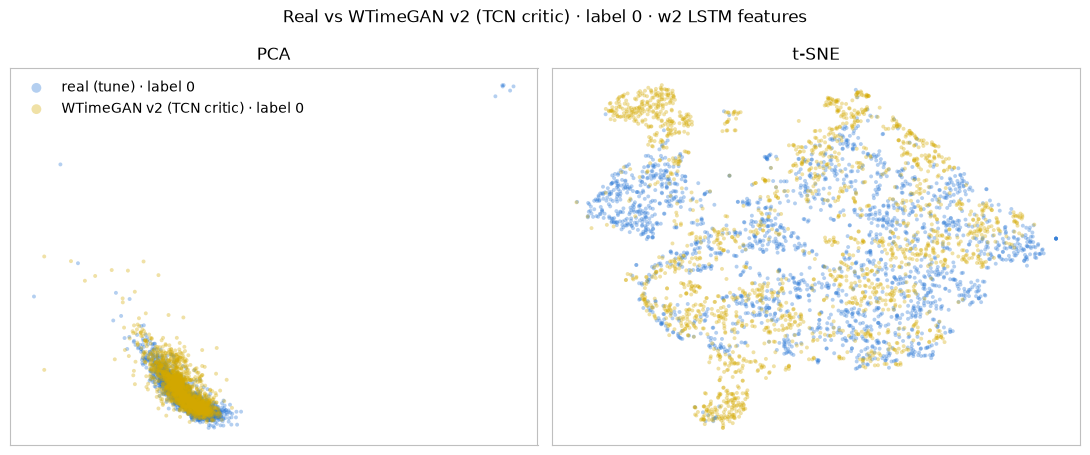

In [16]:
# One figure per GAN (real vs that GAN): with both GANs in one plot the clouds hide each other.
for label in GAN_LABELS:
    for gan in COMPARE:
        feats = {f"real (tune) · label {label}": features["real", label],
                 f"{LABELS[gan]} · label {label}": features[gan, label]}
        gp.plot_embedding_2d(feats, f"Real vs {LABELS[gan]} · label {label} · w2 LSTM features", seed=SEED,
                             save_path=EVAL_DIR / f"embedding_label{label}_{gan}.png")
        plt.show()

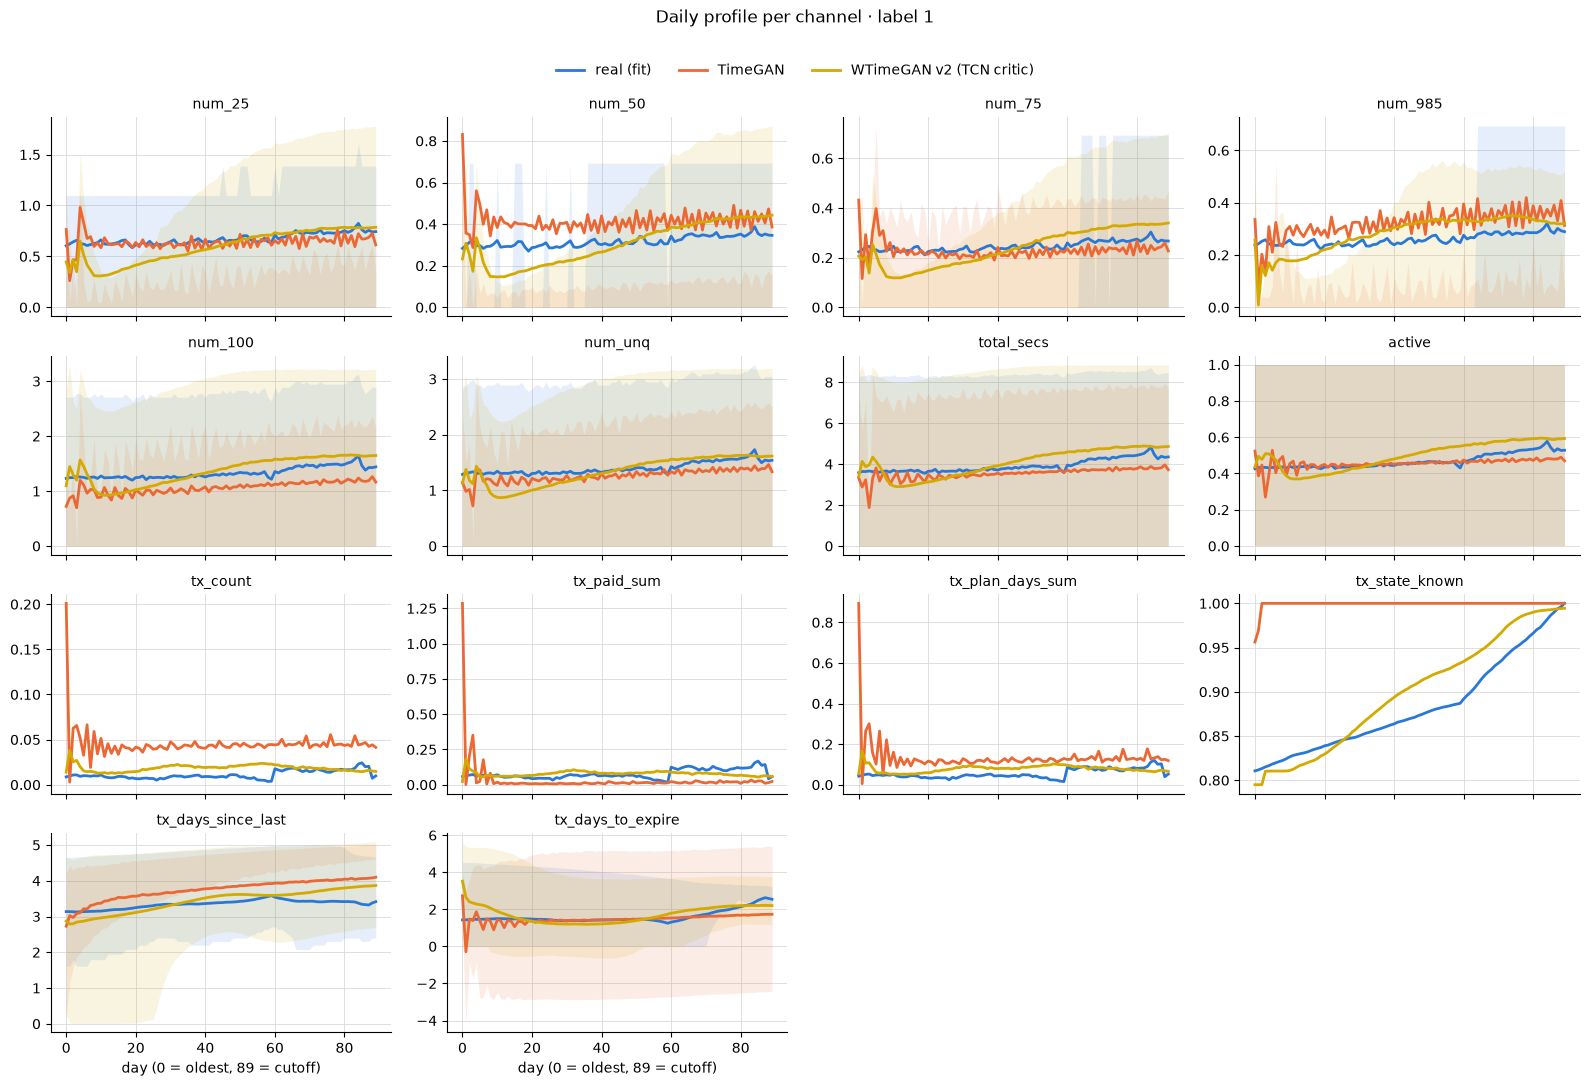

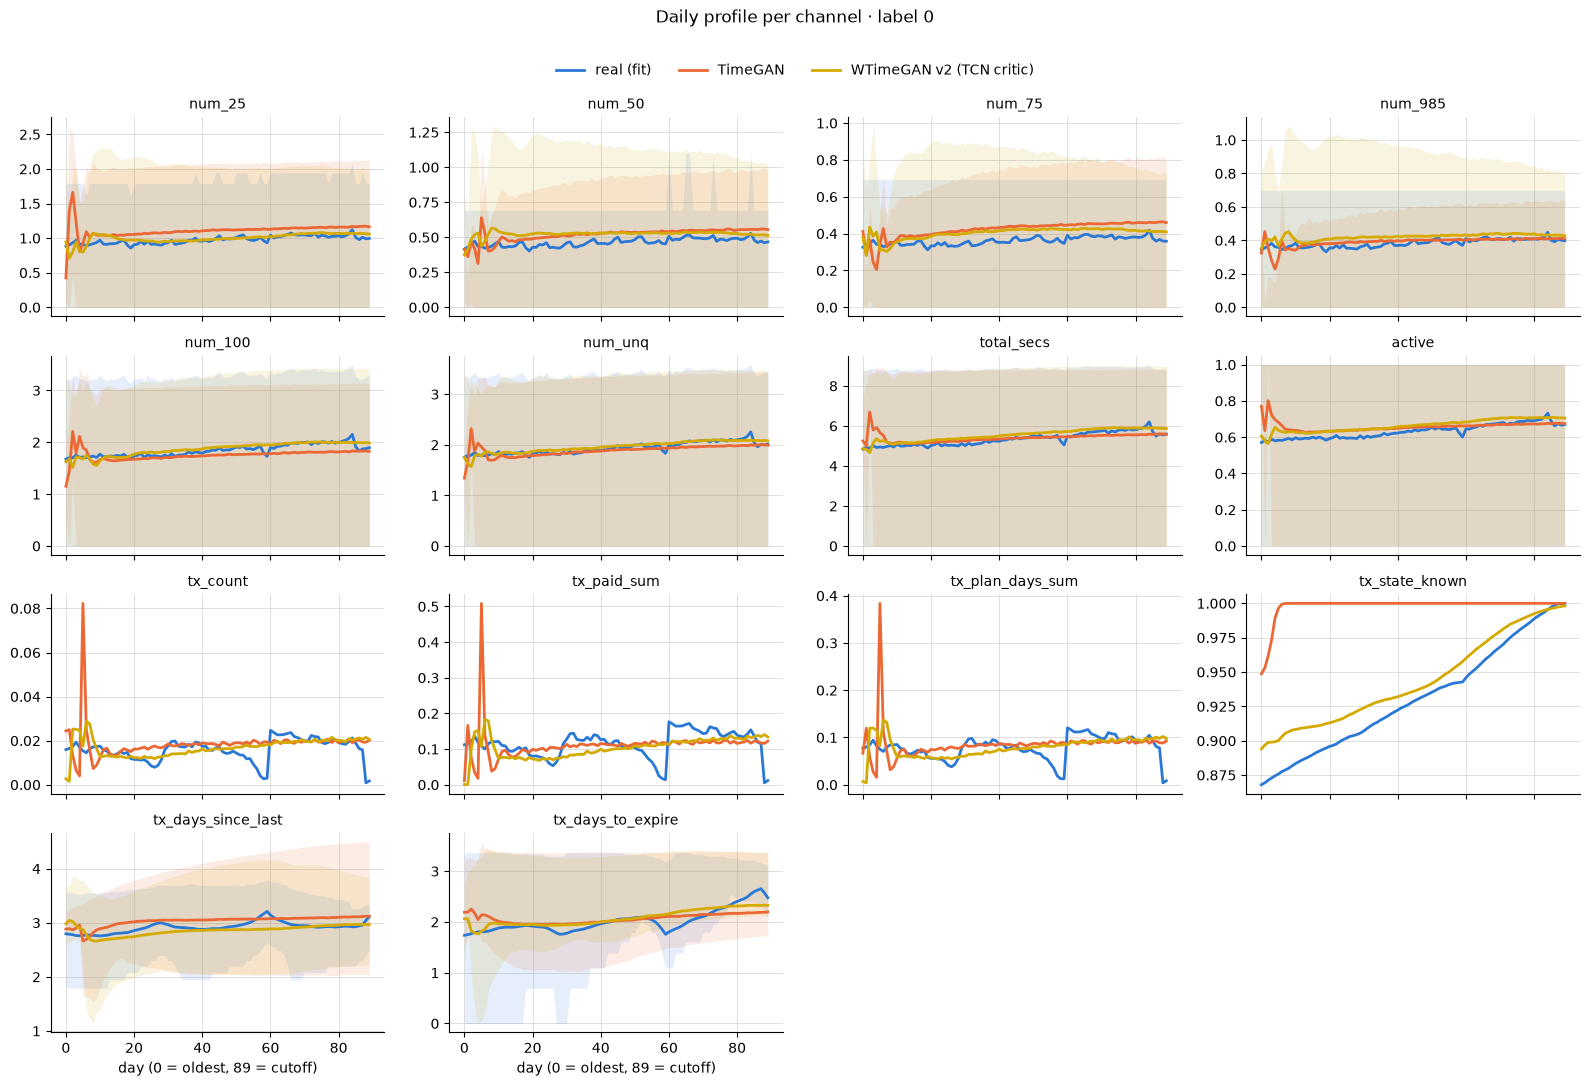

In [17]:
for label in GAN_LABELS:
    sources = {"real (fit)": real["fit", label]}
    sources.update({LABELS[gan]: runs[gan, label]["synthetic"] for gan in COMPARE})
    gp.plot_daily_profiles(sources, MODEL_CHANNELS, f"Daily profile per channel · label {label}",
                           save_path=EVAL_DIR / f"daily_profiles_label{label}.png")
    plt.show()

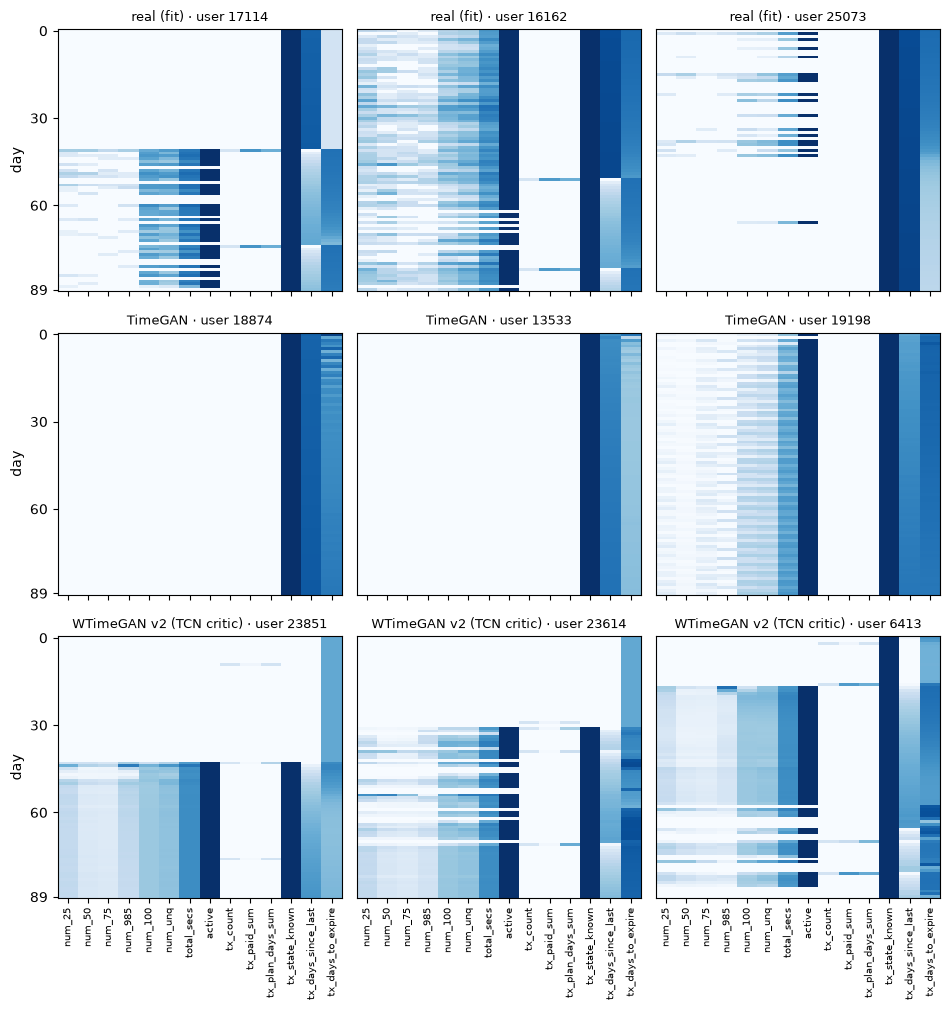

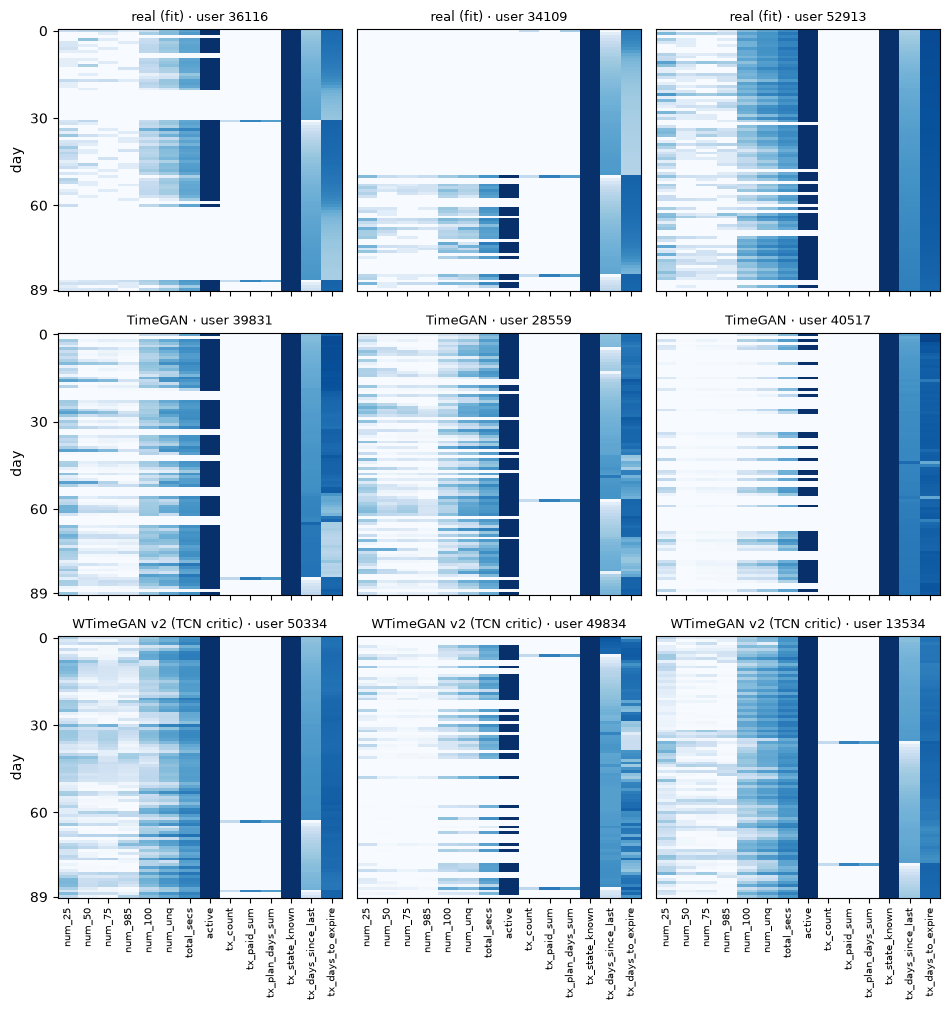

In [18]:
for label in GAN_LABELS:
    sources = {"real (fit)": real["fit", label]}
    sources.update({LABELS[gan]: runs[gan, label]["synthetic"] for gan in COMPARE})
    gp.plot_user_slices(sources, MODEL_CHANNELS, n_users=3, seed=SEED,
                        save_path=EVAL_DIR / f"user_slices_label{label}.png")
    plt.show()

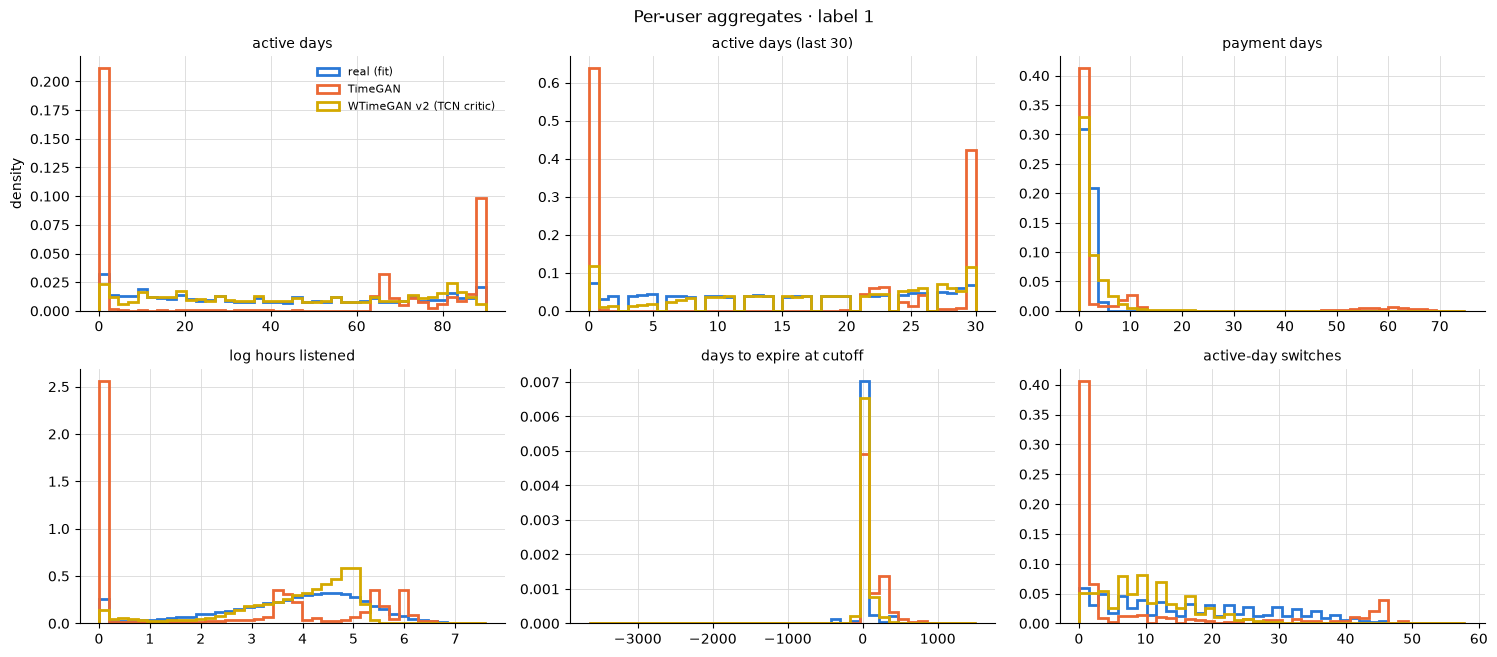

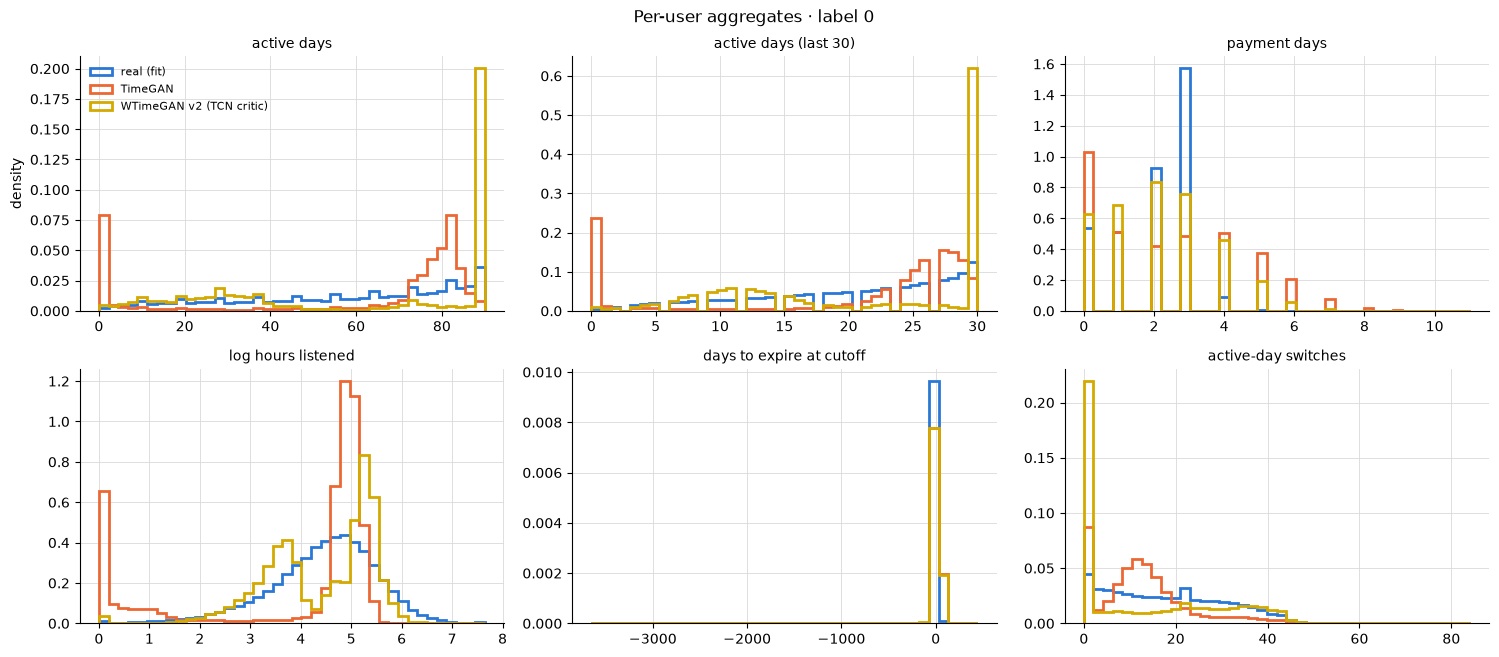

In [19]:
for label in GAN_LABELS:
    aggs = {"real (fit)": gq.user_aggregates(real["fit", label], MODEL_CHANNELS)}
    aggs.update({LABELS[gan]: gq.user_aggregates(runs[gan, label]["synthetic"], MODEL_CHANNELS) for gan in COMPARE})
    gp.plot_aggregate_hists(aggs, save_path=EVAL_DIR / f"aggregates_label{label}.png")
    plt.suptitle(f"Per-user aggregates · label {label}", y=1.02)
    plt.show()

### 5.5 Payment-state consistency

Same domain checks as section 4.3 of the first notebook (payments must reset the state channels; real manual payers pay around their expiry).

In [20]:
variants = {}
for label in GAN_LABELS:
    variants["real (fit)", label] = real["fit", label]
    variants["real (tune)", label] = real["tune", label]
    for gan in COMPARE:
        raw, upper = runs[gan, label]["raw"], real["fit", label].max(axis=(0, 1))
        variants[f"{LABELS[gan]} (generated state)", label] = postprocess(raw, specs, seed=SEED, upper=upper)
        variants[f"{LABELS[gan]} (state rebuilt)", label] = postprocess(raw, specs, seed=SEED, rebuild_state=True,
                                                                        upper=upper)

consistency = pd.DataFrame(
    [{"label": label, "source": source,
      **gq.payment_state_consistency(X, MODEL_CHANNELS),
      "payments within 3 days of expiry": gq.payments_near_expiry(X, MODEL_CHANNELS)}
     for (source, label), X in variants.items()]
).set_index(["label", "source"])
consistency.to_csv(EVAL_DIR / "trajectory_consistency.csv")
consistency.round(3)

pay day: since_last = 0  \
label source                                                                
1     real (fit)                                                    1.000   
      real (tune)                                                   1.000   
      TimeGAN (generated state)                                     0.978   
      TimeGAN (state rebuilt)                                       1.000   
      WTimeGAN v2 (TCN critic) (generated state)                    0.923   
      WTimeGAN v2 (TCN critic) (state rebuilt)                      1.000   
0     real (fit)                                                    1.000   
      real (tune)                                                   1.000   
      TimeGAN (generated state)                                     0.947   
      TimeGAN (state rebuilt)                                       1.000   
      WTimeGAN v2 (TCN critic) (generated state)                    0.927   
      WTimeGAN v2 (TCN critic) (state rebuilt)                      1.000   

                                                  no pay: since_last + 1  \
label source                                                               
1     real (fit)                                                   1.000   
      real (tune)                                                  1.000   
      TimeGAN (generated state)                                    0.834   
      TimeGAN (state rebuilt)                                      1.000   
      WTimeGAN v2 (TCN critic) (generated state)                   0.727   
      WTimeGAN v2 (TCN critic) (state rebuilt)                     1.000   
0     real (fit)                                                   1.000   
      real (tune)                                                  1.000   
      TimeGAN (generated state)                                    0.862   
      TimeGAN (state rebuilt)                                      1.000   
      WTimeGAN v2 (TCN critic) (generated state)                   0.829   
      WTimeGAN v2 (TCN critic) (state rebuilt)                     1.000   

                                                  no pay: to_expire - 1  \
label source                                                              
1     real (fit)                                                  1.000   
      real (tune)                                                 1.000   
      TimeGAN (generated state)                                   0.586   
      TimeGAN (state rebuilt)                                     1.000   
      WTimeGAN v2 (TCN critic) (generated state)                  0.512   
      WTimeGAN v2 (TCN critic) (state rebuilt)                    1.000   
0     real (fit)                                                  1.000   
      real (tune)                                                 1.000   
      TimeGAN (generated state)                                   0.473   
      TimeGAN (state rebuilt)                                     1.000   
      WTimeGAN v2 (TCN critic) (generated state)                  0.488   
      WTimeGAN v2 (TCN critic) (state rebuilt)                    1.000   

                                                  pay day: to_expire = max(prev-1,0) + plan  \
label source                                                                                  
1     real (fit)                                                                      0.933   
      real (tune)                                                                     0.929   
      TimeGAN (generated state)                                                       0.215   
      TimeGAN (state rebuilt)                                                         1.000   
      WTimeGAN v2 (TCN critic) (generated state)                                      0.054   
      WTimeGAN v2 (TCN critic) (state rebuilt)                                        1.000   
0     real (fit)                                                                      0.975   


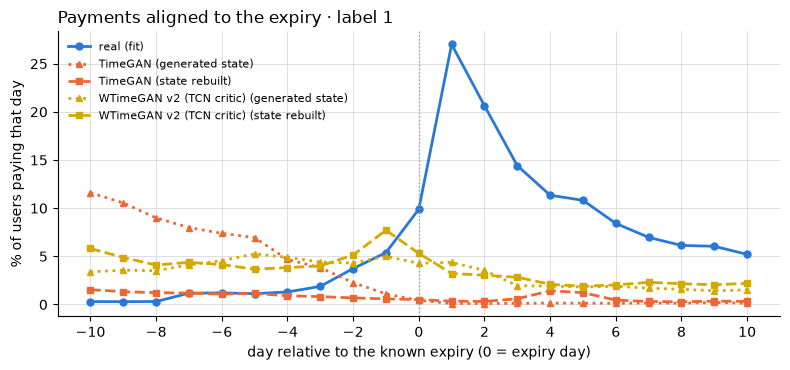

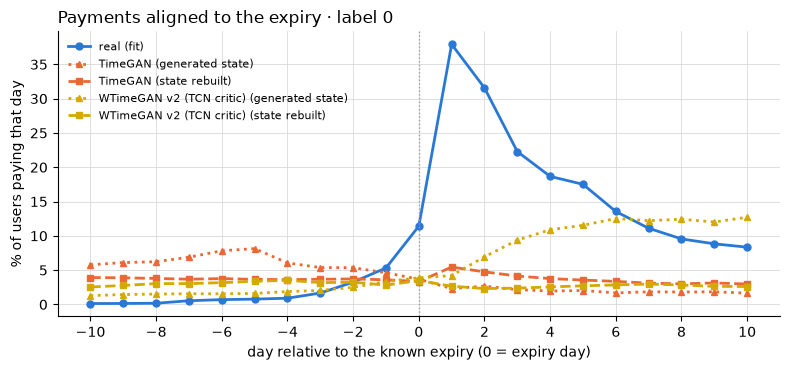

In [21]:
# Payment rate aligned to the expiry: real users renew right after it.
for label in GAN_LABELS:
    curves = {source: gq.pay_by_expiry(X, MODEL_CHANNELS)[0]
              for (source, lab), X in variants.items() if lab == label and source != "real (tune)"}
    gp.plot_pay_by_expiry(curves, f"Payments aligned to the expiry · label {label}",
                          save_path=EVAL_DIR / f"pay_by_expiry_label{label}.png")
    plt.show()

## 6. Bridge w2 -> w5 with the v2 users

Same scenarios and protocol as section 5 of the first notebook, only for v2: the w2 churn classifiers (LSTM, GRU) with synthetic churners added (+50 %, +100 %) or trained on synthetic users only (TSTR), and the w2 trajectory models with synthetic users of both classes. The baseline is retrained here (the paired bootstrap needs its predictions). TimeGAN gains are read from `artifacts/bridge/`.

With `RUN_BRIDGE = False` (default) the cells below show the saved results of `artifacts/bridge_tcn/` without retraining.

Reminder from the first notebook: one training seed; the bootstrap covers sampling noise on March, not the variation of retraining, so differences of a few thousandths of AUC are within training noise.

In [22]:
if RUN_BRIDGE:
    BRIDGE_DIR.mkdir(parents=True, exist_ok=True)
    fit_rows = data.rows("fit")
    n_fit_churn = int(data.y_all[fit_rows].sum())
    n_fit_stay = len(fit_rows) - n_fit_churn

    bridge_runs = {m: {} for m in BRIDGE_MODELS}
    bridge_tunes = {m: {} for m in BRIDGE_MODELS}
    for model_name in BRIDGE_MODELS:
        print(f"\n===== {model_name.upper()} · baseline =====")
        bridge_runs[model_name]["baseline"], bridge_tunes[model_name]["baseline"] = bridge.run_scenario(
            data, model_name, fit_rows, device=DEVICE, seed=SEED)

    synthetic = {label: runs[NEW_GAN, label]["synthetic"] for label in GAN_LABELS}
    data_aug, synth_rows = bridge.augment(data, synthetic)
    scenarios = {
        f"{NEW_GAN} +{int(f * 100)}% churn": np.concatenate(
            [fit_rows, bridge.take(synth_rows[1], int(round(f * n_fit_churn)), seed=SEED)])
        for f in AUG_FRACTIONS
    }
    scenarios[f"{NEW_GAN} TSTR"] = np.concatenate([
        bridge.take(synth_rows[1], min(n_fit_churn, len(synth_rows[1])), seed=SEED),
        bridge.take(synth_rows[0], min(n_fit_stay, len(synth_rows[0])), seed=SEED)])
    for model_name in BRIDGE_MODELS:
        for scenario, rows in scenarios.items():
            print(f"\n===== {model_name.upper()} · {scenario} ({len(rows):,} rows) =====")
            bridge_runs[model_name][scenario], bridge_tunes[model_name][scenario] = bridge.run_scenario(
                data_aug, model_name, rows, device=DEVICE, seed=SEED)
    del data_aug

In [23]:
for model_name in BRIDGE_MODELS:
    print(f"\n===== {model_name.upper()} =====")
    if RUN_BRIDGE:
        table = bridge.scenario_table(bridge_runs[model_name], bridge_tunes[model_name])
        table.to_csv(BRIDGE_DIR / f"scenarios_{model_name}.csv")
        versus = bridge.versus_baseline(bridge_runs[model_name], bridge_tunes[model_name], "baseline")
        versus.to_csv(BRIDGE_DIR / f"versus_baseline_{model_name}.csv")
    else:
        table = pd.read_csv(BRIDGE_DIR / f"scenarios_{model_name}.csv", index_col="scenario")
        versus = pd.read_csv(BRIDGE_DIR / f"versus_baseline_{model_name}.csv", index_col=["scenario", "metric"])
    display(table.round(4))
    print(f"----- {model_name.upper()}: scenario - baseline -----")
    display(versus.round(4))


===== LSTM =====


,train users,train churn rate,best epoch,AUC-ROC,AUC-PR,F1,precision,recall,log-loss,brier,threshold
scenario,,,,,,,,,,,
baseline,83814,0.3215,13,0.7678,0.7057,0.6707,0.6390,0.7057,0.5860,0.2015,0.30
wtimegan_tcn +50% churn,97288,0.4155,13,0.7606,0.6934,0.6676,0.6272,0.7136,0.5901,0.2028,0.29
wtimegan_tcn +100% churn,110761,0.4866,13,0.7639,0.6947,0.6715,0.6279,0.7216,0.5884,0.2018,0.29
wtimegan_tcn TSTR,83814,0.3215,1,0.6657,0.6208,0.5582,0.5968,0.5243,1.6322,0.3244,0.01


----- LSTM: scenario - baseline -----


Δ vs baseline              Δ IC95  \
scenario                 metric                                        
wtimegan_tcn +50% churn  AUC-ROC         -0.0072  [-0.0080, -0.0063]   
                         AUC-PR          -0.0123  [-0.0134, -0.0110]   
                         F1              -0.0030  [-0.0046, -0.0014]   
                         Log-loss         0.0041    [0.0033, 0.0048]   
wtimegan_tcn +100% churn AUC-ROC         -0.0039  [-0.0047, -0.0031]   
                         AUC-PR          -0.0110  [-0.0122, -0.0098]   
                         F1               0.0008   [-0.0005, 0.0024]   
                         Log-loss         0.0024    [0.0015, 0.0032]   
wtimegan_tcn TSTR        AUC-ROC         -0.1021  [-0.1053, -0.0989]   
                         AUC-PR          -0.0848  [-0.0889, -0.0807]   
                         F1              -0.1125  [-0.1164, -0.1086]   
                         Log-loss         1.0462    [1.0348, 1.0586]   

                                   significant  DeLong p (AUC-ROC)  
scenario                 metric                                     
wtimegan_tcn +50% churn  AUC-ROC          True                 0.0  
                         AUC-PR           True                 NaN  
                         F1               True                 NaN  
                         Log-loss         True                 NaN  
wtimegan_tcn +100% churn AUC-ROC          True                 0.0  
                         AUC-PR           True                 NaN  
                         F1              False                 NaN  
                         Log-loss         True                 NaN  
wtimegan_tcn TSTR        AUC-ROC          True                 0.0  
                         AUC-PR           True                 NaN  
                         F1               True                 NaN  
                         Log-loss         True                 NaN


===== GRU =====


,train users,train churn rate,best epoch,AUC-ROC,AUC-PR,F1,precision,recall,log-loss,brier,threshold
scenario,,,,,,,,,,,
baseline,83814,0.3215,10,0.7705,0.7039,0.6767,0.6519,0.7034,0.5824,0.1996,0.31
wtimegan_tcn +50% churn,97288,0.4155,4,0.7731,0.7065,0.6794,0.6532,0.7077,0.5755,0.1965,0.32
wtimegan_tcn +100% churn,110761,0.4866,4,0.7729,0.7066,0.6795,0.6467,0.7159,0.5789,0.1982,0.30
wtimegan_tcn TSTR,83814,0.3215,1,0.7029,0.6347,0.5968,0.5876,0.6063,1.7123,0.2993,0.01


----- GRU: scenario - baseline -----


Δ vs baseline              Δ IC95  \
scenario                 metric                                        
wtimegan_tcn +50% churn  AUC-ROC          0.0026    [0.0018, 0.0035]   
                         AUC-PR           0.0026    [0.0014, 0.0039]   
                         F1               0.0027    [0.0011, 0.0044]   
                         Log-loss        -0.0069  [-0.0078, -0.0060]   
wtimegan_tcn +100% churn AUC-ROC          0.0024    [0.0016, 0.0032]   
                         AUC-PR           0.0027    [0.0015, 0.0038]   
                         F1               0.0028    [0.0013, 0.0046]   
                         Log-loss        -0.0035  [-0.0042, -0.0027]   
wtimegan_tcn TSTR        AUC-ROC         -0.0676  [-0.0704, -0.0648]   
                         AUC-PR          -0.0693  [-0.0729, -0.0656]   
                         F1              -0.0798  [-0.0831, -0.0766]   
                         Log-loss         1.1299    [1.1167, 1.1439]   

                                   significant  DeLong p (AUC-ROC)  
scenario                 metric                                     
wtimegan_tcn +50% churn  AUC-ROC          True                 0.0  
                         AUC-PR           True                 NaN  
                         F1               True                 NaN  
                         Log-loss         True                 NaN  
wtimegan_tcn +100% churn AUC-ROC          True                 0.0  
                         AUC-PR           True                 NaN  
                         F1               True                 NaN  
                         Log-loss         True                 NaN  
wtimegan_tcn TSTR        AUC-ROC          True                 0.0  
                         AUC-PR           True                 NaN  
                         F1               True                 NaN  
                         Log-loss         True                 NaN

In [24]:
if RUN_BRIDGE:
    fit_churn_rate = float(data.y_all[fit_rows].mean())
    traj_runs = {m: {} for m in TRAJ_MODELS}
    for model_name in TRAJ_MODELS:
        print(f"\n===== {model_name.upper()} trajectory · baseline =====")
        traj_runs[model_name]["baseline"] = bridge.run_trajectory_scenario(
            data, model_name, fit_rows, device=DEVICE, seed=SEED)

    data_aug, synth_rows = bridge.augment(data, synthetic)
    traj_scenarios = {
        f"{NEW_GAN} +{int(f * 100)}%": np.concatenate([
            fit_rows, bridge.mixed_synthetic_rows(synth_rows, int(round(f * len(fit_rows))),
                                                  fit_churn_rate, seed=SEED)])
        for f in TRAJ_FRACTIONS
    }
    n_tstr = min(len(fit_rows), int(len(synth_rows[1]) / max(fit_churn_rate, 1e-9)),
                 int(len(synth_rows[0]) / max(1 - fit_churn_rate, 1e-9)))
    traj_scenarios[f"{NEW_GAN} TSTR"] = bridge.mixed_synthetic_rows(synth_rows, n_tstr, fit_churn_rate, seed=SEED)
    for model_name in TRAJ_MODELS:
        for scenario, rows in traj_scenarios.items():
            print(f"\n===== {model_name.upper()} trajectory · {scenario} ({len(rows):,} rows) =====")
            traj_runs[model_name][scenario] = bridge.run_trajectory_scenario(
                data_aug, model_name, rows, device=DEVICE, seed=SEED)
    del data_aug

In [25]:
traj_reports = {}
for model_name in TRAJ_MODELS:
    if RUN_BRIDGE:
        traj_reports[model_name] = bridge.trajectory_report(data, traj_runs[model_name])
        table = bridge.trajectory_summary(traj_reports[model_name], traj_runs[model_name])
        table.to_csv(BRIDGE_DIR / f"trajectory_scenarios_{model_name}.csv")
        versus = bridge.trajectory_versus_baseline(traj_reports[model_name], "baseline", seed=SEED)
        versus.to_csv(BRIDGE_DIR / f"trajectory_versus_baseline_{model_name}.csv")
    else:
        table = pd.read_csv(BRIDGE_DIR / f"trajectory_scenarios_{model_name}.csv", index_col="scenario")
        versus = pd.read_csv(BRIDGE_DIR / f"trajectory_versus_baseline_{model_name}.csv",
                             index_col=["scenario", "metric"])
    print(f"\n===== {model_name.upper()} trajectory =====")
    display(table.round(4))
    print(f"----- {model_name.upper()} trajectory: scenario - baseline -----")
    display(versus.round(4))


===== LSTM trajectory =====


,train users,best epoch,stop loss,listening MAE,skill vs persistence,active AUC,pay AUC,pay AP,weekly pay AP,MAE paid (NTD),MAE plan days
scenario,,,,,,,,,,,
baseline,83814,19,2.7390,1.0331,0.0290,0.8049,0.8947,0.1779,0.8897,60.6318,8.8452
wtimegan_tcn +50%,125721,16,2.7538,1.0163,0.0448,0.8044,0.8898,0.1658,0.8946,56.1211,7.9569
wtimegan_tcn +100%,167628,19,2.7581,1.0275,0.0342,0.8042,0.8850,0.1735,0.9006,56.3398,7.8466
wtimegan_tcn TSTR,83814,1,3.8081,1.0244,0.0371,0.7860,0.6604,0.0599,0.4355,68.8186,9.4312


----- LSTM trajectory: scenario - baseline -----


Δ vs baseline  \
scenario           metric                                    
wtimegan_tcn +50%  listening MAE (per user)        -0.0168   
                   active AUC                      -0.0004   
                   active AP                        0.0003   
                   pay AUC                         -0.0048   
                   pay AP                          -0.0121   
                   pay_week AUC                     0.0003   
                   pay_week AP                      0.0049   
wtimegan_tcn +100% listening MAE (per user)        -0.0056   
                   active AUC                      -0.0007   
                   active AP                       -0.0000   
                   pay AUC                         -0.0097   
                   pay AP                          -0.0044   
                   pay_week AUC                     0.0008   
                   pay_week AP                      0.0109   
wtimegan_tcn TSTR  listening MAE (per user)        -0.0087   
                   active AUC                      -0.0189   
                   active AP                       -0.0134   
                   pay AUC                         -0.2343   
                   pay AP                          -0.1180   
                   pay_week AUC                    -0.2776   
                   pay_week AP                     -0.4542   

                                                         Δ IC95  significant  
scenario           metric                                                     
wtimegan_tcn +50%  listening MAE (per user)  [-0.0173, -0.0163]         True  
                   active AUC                [-0.0008, -0.0001]         True  
                   active AP                  [-0.0000, 0.0006]        False  
                   pay AUC                   [-0.0059, -0.0039]         True  
                   pay AP                    [-0.0146, -0.0100]         True  
                   pay_week AUC               [-0.0003, 0.0009]        False  
                   pay_week AP                 [0.0006, 0.0094]         True  
wtimegan_tcn +100% listening MAE (per user)  [-0.0061, -0.0051]         True  
                   active AUC                [-0.0011, -0.0003]         True  
                   active AP                  [-0.0004, 0.0003]        False  
                   pay AUC                   [-0.0108, -0.0084]         True  
                   pay AP                    [-0.0065, -0.0024]         True  
                   pay_week AUC                [0.0003, 0.0013]         True  
                   pay_week AP                 [0.0070, 0.0150]         True  
wtimegan_tcn TSTR  listening MAE (per user)  [-0.0099, -0.0074]         True  
                   active AUC                [-0.0198, -0.0181]         True  
                   active AP                 [-0.0141, -0.0127]         True  
                   pay AUC                   [-0.2385, -0.2302]         True  
                   pay AP                    [-0.1222, -0.1143]         True  
                   pay_week AUC              [-0.2824, -0.2733]         True  
                   pay_week AP               [-0.4624, -0.4459]         True


===== GRU trajectory =====


,train users,best epoch,stop loss,listening MAE,skill vs persistence,active AUC,pay AUC,pay AP,weekly pay AP,MAE paid (NTD),MAE plan days
scenario,,,,,,,,,,,
baseline,83814,17,2.7266,1.0217,0.0396,0.8075,0.8954,0.1775,0.9056,55.2877,9.1239
wtimegan_tcn +50%,125721,10,2.7518,1.0358,0.0264,0.8029,0.8951,0.1668,0.9148,50.4089,7.8306
wtimegan_tcn +100%,167628,11,2.7739,1.0225,0.0389,0.8027,0.8929,0.1666,0.9013,50.2615,7.7086
wtimegan_tcn TSTR,83814,1,3.9386,1.0119,0.0489,0.7890,0.6545,0.0534,0.3769,74.9469,9.8555


----- GRU trajectory: scenario - baseline -----


Δ vs baseline  \
scenario           metric                                    
wtimegan_tcn +50%  listening MAE (per user)         0.0141   
                   active AUC                      -0.0046   
                   active AP                       -0.0037   
                   pay AUC                         -0.0003   
                   pay AP                          -0.0107   
                   pay_week AUC                     0.0006   
                   pay_week AP                      0.0092   
wtimegan_tcn +100% listening MAE (per user)         0.0007   
                   active AUC                      -0.0048   
                   active AP                       -0.0044   
                   pay AUC                         -0.0025   
                   pay AP                          -0.0110   
                   pay_week AUC                    -0.0031   
                   pay_week AP                     -0.0043   
wtimegan_tcn TSTR  listening MAE (per user)        -0.0099   
                   active AUC                      -0.0185   
                   active AP                       -0.0137   
                   pay AUC                         -0.2409   
                   pay AP                          -0.1242   
                   pay_week AUC                    -0.2967   
                   pay_week AP                     -0.5287   

                                                         Δ IC95  significant  
scenario           metric                                                     
wtimegan_tcn +50%  listening MAE (per user)    [0.0137, 0.0145]         True  
                   active AUC                [-0.0049, -0.0043]         True  
                   active AP                 [-0.0040, -0.0034]         True  
                   pay AUC                    [-0.0012, 0.0006]        False  
                   pay AP                    [-0.0130, -0.0083]         True  
                   pay_week AUC                [0.0001, 0.0011]         True  
                   pay_week AP                 [0.0057, 0.0121]         True  
wtimegan_tcn +100% listening MAE (per user)    [0.0002, 0.0012]         True  
                   active AUC                [-0.0052, -0.0045]         True  
                   active AP                 [-0.0048, -0.0041]         True  
                   pay AUC                   [-0.0036, -0.0015]         True  
                   pay AP                    [-0.0137, -0.0086]         True  
                   pay_week AUC              [-0.0037, -0.0025]         True  
                   pay_week AP               [-0.0075, -0.0008]         True  
wtimegan_tcn TSTR  listening MAE (per user)  [-0.0110, -0.0086]         True  
                   active AUC                [-0.0193, -0.0176]         True  
                   active AP                 [-0.0143, -0.0129]         True  
                   pay AUC                   [-0.2449, -0.2367]         True  
                   pay AP                    [-0.1281, -0.1203]         True  
                   pay_week AUC              [-0.3014, -0.2921]         True  
                   pay_week AP               [-0.5373, -0.5200]         True

### 6.1 Gains over the baseline: TimeGAN vs v2

TimeGAN rows come from `artifacts/bridge/` (their own baseline run in the first notebook); v2 rows from the baseline of this notebook.

In [26]:
def gains_from(tables, key, deltas):
    rows = []
    for model_name, table in tables.items():
        base = table.loc["baseline"]
        for scenario, row in table.drop(index="baseline").iterrows():
            rows.append({key: model_name.upper(), "scenario": scenario,
                         **{name: sign * (row[col] - base[col]) for name, (col, sign) in deltas.items()}})
    return pd.DataFrame(rows)


def only_compared(df):
    return df[df["scenario"].str.split(" ").str[0].isin(COMPARE)]


clf_tables = {m: pd.read_csv(BRIDGE_DIR / f"scenarios_{m}.csv", index_col="scenario") for m in BRIDGE_MODELS}
new_gains = gains_from(clf_tables, "classifier", {"Δ AUC-ROC": ("AUC-ROC", 1), "Δ AUC-PR": ("AUC-PR", 1),
                                                  "Δ F1": ("F1", 1)})
new_gains.set_index(["classifier", "scenario"]).to_csv(BRIDGE_DIR / "gains_vs_baseline.csv")
gains = only_compared(pd.concat([pd.read_csv(OLD_BRIDGE_DIR / "gains_vs_baseline.csv"), new_gains]))
display(gains.set_index(["classifier", "scenario"]).sort_index().round(4))

traj_tables = {m: pd.read_csv(BRIDGE_DIR / f"trajectory_scenarios_{m}.csv", index_col="scenario") for m in TRAJ_MODELS}
new_traj = gains_from(traj_tables, "model", {"Δ listening MAE (lower = better)": ("listening MAE", 1),
                                             "Δ active AUC": ("active AUC", 1), "Δ pay AP": ("pay AP", 1),
                                             "Δ weekly pay AP": ("weekly pay AP", 1)})
new_traj.set_index(["model", "scenario"]).to_csv(BRIDGE_DIR / "trajectory_gains_vs_baseline.csv")
traj_gains = only_compared(pd.concat([pd.read_csv(OLD_BRIDGE_DIR / "trajectory_gains_vs_baseline.csv"), new_traj]))
display(traj_gains.set_index(["model", "scenario"]).sort_index().round(4))

Δ AUC-ROC  Δ AUC-PR    Δ F1
classifier scenario                                             
GRU        timegan +100% churn          0.0042    0.0092 -0.0088
           timegan +50% churn          -0.0094   -0.0126 -0.0003
           timegan TSTR                -0.1239   -0.1403 -0.2354
           wtimegan_tcn +100% churn     0.0024    0.0027  0.0028
           wtimegan_tcn +50% churn      0.0026    0.0026  0.0027
           wtimegan_tcn TSTR           -0.0676   -0.0693 -0.0798
LSTM       timegan +100% churn          0.0015   -0.0007  0.0075
           timegan +50% churn          -0.0010   -0.0065  0.0038
           timegan TSTR                -0.1805   -0.2309 -0.3965
           wtimegan_tcn +100% churn    -0.0039   -0.0110  0.0008
           wtimegan_tcn +50% churn     -0.0072   -0.0123 -0.0030
           wtimegan_tcn TSTR           -0.1021   -0.0848 -0.1125

Δ listening MAE (lower = better)  Δ active AUC  \
model scenario                                                             
GRU   timegan +100%                                 0.0069       -0.0054   
      timegan +50%                                  0.0026       -0.0025   
      timegan TSTR                                  0.0714       -0.0787   
      wtimegan_tcn +100%                            0.0007       -0.0048   
      wtimegan_tcn +50%                             0.0141       -0.0046   
      wtimegan_tcn TSTR                            -0.0099       -0.0185   
LSTM  timegan +100%                                -0.0138        0.0008   
      timegan +50%                                 -0.0060        0.0005   
      timegan TSTR                                  0.0316       -0.0578   
      wtimegan_tcn +100%                           -0.0056       -0.0007   
      wtimegan_tcn +50%                            -0.0168       -0.0004   
      wtimegan_tcn TSTR                            -0.0087       -0.0189   

                          Δ pay AP  Δ weekly pay AP  
model scenario                                       
GRU   timegan +100%        -0.0096          -0.0021  
      timegan +50%         -0.0075           0.0058  
      timegan TSTR         -0.1519          -0.7253  
      wtimegan_tcn +100%   -0.0110          -0.0043  
      wtimegan_tcn +50%    -0.0107           0.0092  
      wtimegan_tcn TSTR    -0.1242          -0.5287  
LSTM  timegan +100%        -0.0028           0.0104  
      timegan +50%         -0.0010           0.0123  
      timegan TSTR         -0.1576          -0.7513  
      wtimegan_tcn +100%   -0.0044           0.0109  
      wtimegan_tcn +50%    -0.0121           0.0049  
      wtimegan_tcn TSTR    -0.1180          -0.4542

## 7. Conclusions

*To be written after the full run.* Questions to answer, in order:

1. **Did v2 train?** Section 4.1: `w_distance` going down at the end, generator weights moving, between-user spread close to real. If not, the next lever is the balance critic/generator (`n_critic`, `d_lr`), not more iterations.
2. **Is it less collapsed than TimeGAN?** Section 5.2 (NN distances, extremes, switches) and 5.4 (t-SNE coverage). Discriminative score clearly below ~0.46 and mean churn probability of synthetic churners close to the real 0.48.
3. **Are payments back?** `no payment` and payment-day rate (5.2, 5.3), payment-state consistency (5.5). Wasserstein is not expected to fix the sparsity of payments by itself (`TIMEGAN_DIAGNOSIS.md`, section 6).
4. **Does it help w2?** Section 6.1, read against training noise (single seed).

## 8. Artifacts

```text
artifacts/
├── wtimegan_tcn/label{0,1}/      # synthetic.npy, raw.npy, upper.npy, history.csv, checkpoint.pt, run.json
├── evaluation_tcn/
│   ├── quality_summary.csv       # 5.1 (TimeGAN, v2)
│   ├── collapse_signals.csv      # 5.2
│   ├── trajectory_consistency.csv  # 5.5
│   ├── wtimegan_tcn/             # history, marginals, aggregates per class
│   └── embedding_*, daily_profiles_*, user_slices_*, aggregates_*, pay_by_expiry_*.png
└── bridge_tcn/                   # same files as artifacts/bridge/, v2 scenarios only
```

`artifacts/timegan/`, `artifacts/wtimegan/`, `artifacts/evaluation/` and `artifacts/bridge/` belong to `w5_gan_models.ipynb` and are only read here.